In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
import math

In [4]:
df_train = pd.read_csv('SalaryData_Train.csv')
df_test = pd.read_csv('SalaryData_Test.csv')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30161 entries, 0 to 30160
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   age            30161 non-null  int64 
 1   workclass      30161 non-null  object
 2   education      30161 non-null  object
 3   educationno    30161 non-null  int64 
 4   maritalstatus  30161 non-null  object
 5   occupation     30161 non-null  object
 6   relationship   30161 non-null  object
 7   race           30161 non-null  object
 8   sex            30161 non-null  object
 9   capitalgain    30161 non-null  int64 
 10  capitalloss    30161 non-null  int64 
 11  hoursperweek   30161 non-null  int64 
 12  native         30161 non-null  object
 13  Salary         30161 non-null  object
dtypes: int64(5), object(9)
memory usage: 3.2+ MB


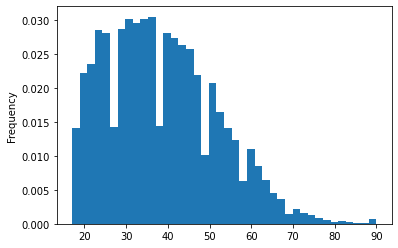

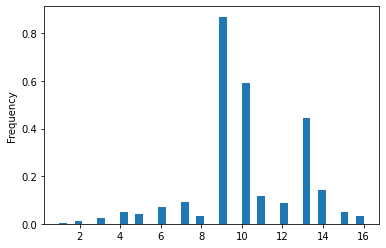

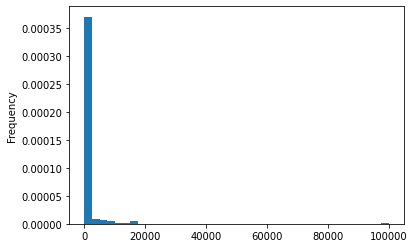

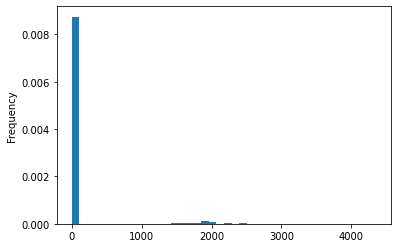

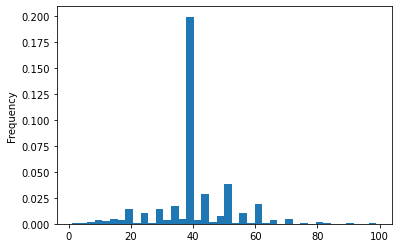

In [25]:
df_train.info()
df_train['age'].plot.hist(bins=40,density=True)
plt.show()
df_train['educationno'].plot.hist(bins=40,density=True)
plt.show()
df_train['capitalgain'].plot.hist(bins=40,density=True)
plt.show()
df_train['capitalloss'].plot.hist(bins=40,density=True)
plt.show()
df_train['hoursperweek'].plot.hist(bins=40,density=True)
plt.show()
# df_train['age'].plot.kde(color='red',linewidth=2)

In [36]:
le = LabelEncoder()
for col in df_train.columns:
    if df_train[col].dtype == 'object':
        df_train[col] = le.fit_transform(df_train[col])

for col in df_test.columns:
    if df_test[col].dtype == 'object':
        df_test[col] = le.fit_transform(df_test[col])
print(df_train.info())
print(df_test.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30161 entries, 0 to 30160
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   age            30161 non-null  int64
 1   workclass      30161 non-null  int64
 2   education      30161 non-null  int64
 3   educationno    30161 non-null  int64
 4   maritalstatus  30161 non-null  int64
 5   occupation     30161 non-null  int64
 6   relationship   30161 non-null  int64
 7   race           30161 non-null  int64
 8   sex            30161 non-null  int64
 9   capitalgain    30161 non-null  int64
 10  capitalloss    30161 non-null  int64
 11  hoursperweek   30161 non-null  int64
 12  native         30161 non-null  int64
 13  Salary         30161 non-null  int64
dtypes: int64(14)
memory usage: 3.2 MB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15060 entries, 0 to 15059
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype
---  ------         ----

In [42]:
X = df_train.drop(columns=['Salary'])
Y = df_train['Salary']
print(X)
print(Y)

       age  workclass  education  educationno  maritalstatus  occupation  \
0       39          5          9           13              4           0   
1       50          4          9           13              2           3   
2       38          2         11            9              0           5   
3       53          2          1            7              2           5   
4       28          2          9           13              2           9   
...    ...        ...        ...          ...            ...         ...   
30156   27          2          7           12              2          12   
30157   40          2         11            9              2           6   
30158   58          2         11            9              6           0   
30159   22          2         11            9              4           0   
30160   52          3         11            9              2           3   

       relationship  race  sex  capitalgain  capitalloss  hoursperweek  native  
0     

In [46]:
def calculate_stats(X, y):
    classes = list(set(y))
    stats = {}
    for c in classes:
        X_c = [X[i] for i in range(len(y)) if y[i] == c]
        prior = len(X_c) / len(y)
        feature_stats = []
        for col in range(len(X[0])):
            vals = [row[col] for row in X_c]
            mean = sum(vals) / len(vals)
            var = sum((x - mean) ** 2 for x in vals) / len(vals) + 1e-9
            feature_stats.append((mean, var))
        stats[c] = {"prior": prior, "features": feature_stats}
    return stats
def predict_single(sample, stats):
    best_class = None
    max_log_posterior = -float('inf')
    for c, c_info in stats.items():
        log_posterior = math.log(c_info["prior"])
        for col, x in enumerate(sample):
            mean, var = c_info["features"][col]
            log_pdf = -0.5 * math.log(2 * math.pi * var) - ((x - mean) ** 2 / (2 * var))
            log_posterior += log_pdf
        if log_posterior > max_log_posterior:
            max_log_posterior = log_posterior
            best_class = c
    return best_class
X_train_list = X.values.tolist()
y_train_list = Y.values.tolist()

X_test_list = df_test.drop(columns=['Salary']).values.tolist()
y_test_list = df_test['Salary'].values.tolist()

model_stats = calculate_stats(X_train_list, y_train_list)
y_pred = [predict_single(sample, model_stats) for sample in X_test_list]

tp = sum(1 for i in range(len(y_test_list)) if y_test_list[i] == 1 and y_pred[i] == 1)
tn = sum(1 for i in range(len(y_test_list)) if y_test_list[i] == 0 and y_pred[i] == 0)
fp = sum(1 for i in range(len(y_test_list)) if y_test_list[i] == 0 and y_pred[i] == 1)
fn = sum(1 for i in range(len(y_test_list)) if y_test_list[i] == 1 and y_pred[i] == 0)
accuracy = (tp + tn) / len(y_test_list)
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

print(f"Accuracy:{accuracy:.4f}")
print(f"Precision:{precision:.4f}")
print(f"Recall:{recall:.4f}")
print(f"F1-Score:{f1_score:.4f}")
print(f"True Negatives (TN): {tn:<6}|False Negatives (FN): {fn}")
print(f"False Positives (FP): {fp:<5}|True Positives (TP): {tp}")



Accuracy:0.7985
Precision:0.6808
Recall:0.3389
F1-Score:0.4525
True Negatives (TN): 10772 |False Negatives (FN): 2446
False Positives (FP): 588  |True Positives (TP): 1254
